In [159]:
import torch
from torch import nn
import matplotlib.pyplot as plt
import numpy as np

In [160]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [161]:
weight = 0.4
bias = 0.2

X = torch.arange(0, 1, 0.02).unsqueeze(1).to(device)
y = X * weight + bias

In [162]:
SPLIT = 40

X_train = X[:SPLIT]
X_test = X[SPLIT:]
y_train = y[:SPLIT]
y_test = y[SPLIT:]

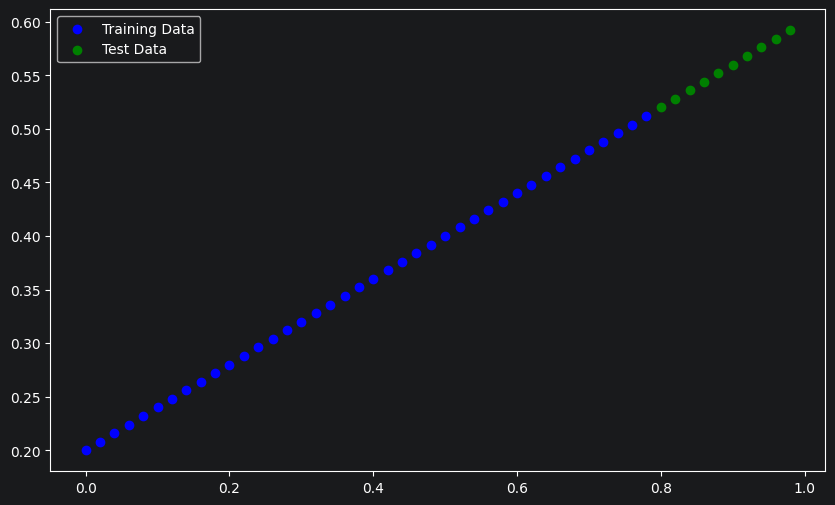

In [163]:
def plot_predictions(X_train = X_train.squeeze(),
                     X_test = X_test.squeeze(),
                     y_train = y_train.squeeze(),
                     y_test = y_test.squeeze(),
                     predictions = None):
    plt.figure(figsize = (10,6))

    plt.scatter(X_train, y_train, c = "b", label = "Training Data")
    plt.scatter(X_test, y_test, c = "g", label = "Test Data")

    if predictions is not None:
        plt.scatter(X_test, predictions, c = "r", label = "Predictions")

    plt.legend()
    plt.plot()
    return
plot_predictions()

In [164]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(1,1,device = device)

    def forward(self,  X :torch.Tensor) -> torch.Tensor:
        return self.layer_1(X)

In [165]:
torch.manual_seed(30)

(OrderedDict([('layer_1.weight', tensor([[0.8015]])),
              ('layer_1.bias', tensor([0.4927]))]),
 None)

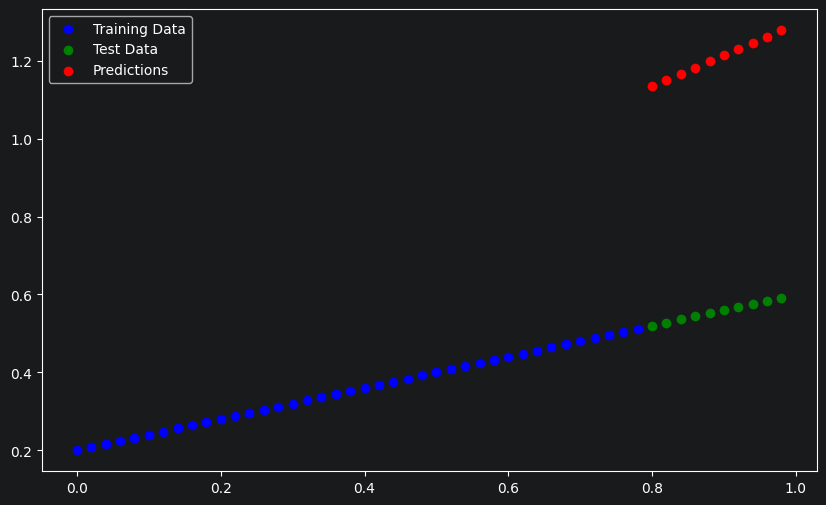

In [166]:
model_3 = LinearRegressionModel()

with torch.inference_mode():
    y_initial_preds = model_3(X_test)

model_3.state_dict(), plot_predictions(predictions=y_initial_preds.cpu())

In [167]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(model_3.parameters(),
                            lr=0.01)

In [168]:
epochs = 200

epoch_count = []
train_loss_values = []
test_loss_values = []

for epoch in range (epochs):
    model_3.train()
    y_train_pred = model_3(X_train)
    loss = loss_fn(y_train_pred, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model_3.eval()
    with torch.inference_mode():
        y_test_preds = model_3(X_test)
        test_loss = loss_fn(y_test_preds, y_test)

    if epoch % 10 == 0:
        epoch_count.append(epoch)
        train_loss_values.append(loss)
        test_loss_values.append(test_loss)
        print(f"Epoch : {epoch} ! Loss : {loss} ! Test loss : {test_loss}")


Epoch : 0 ! Loss : 0.44930610060691833 ! Test loss : 0.6365789175033569
Epoch : 10 ! Loss : 0.3340962529182434 ! Test loss : 0.5018690824508667
Epoch : 20 ! Loss : 0.2188863754272461 ! Test loss : 0.36715924739837646
Epoch : 30 ! Loss : 0.10411930084228516 ! Test loss : 0.2334582358598709
Epoch : 40 ! Loss : 0.05407634377479553 ! Test loss : 0.1480485200881958
Epoch : 50 ! Loss : 0.04476483538746834 ! Test loss : 0.11311902850866318
Epoch : 60 ! Loss : 0.04079354554414749 ! Test loss : 0.09736204147338867
Epoch : 70 ! Loss : 0.03730354085564613 ! Test loss : 0.08634205162525177
Epoch : 80 ! Loss : 0.03386538103222847 ! Test loss : 0.07875647395849228
Epoch : 90 ! Loss : 0.030436938628554344 ! Test loss : 0.0704839900135994
Epoch : 100 ! Loss : 0.026999905705451965 ! Test loss : 0.06221151351928711
Epoch : 110 ! Loss : 0.023563433438539505 ! Test loss : 0.05462590605020523
Epoch : 120 ! Loss : 0.02013498544692993 ! Test loss : 0.046353429555892944
Epoch : 130 ! Loss : 0.0166962742805480

In [169]:
model_3.state_dict()

OrderedDict([('layer_1.weight', tensor([[0.4033]])),
             ('layer_1.bias', tensor([0.1937]))])

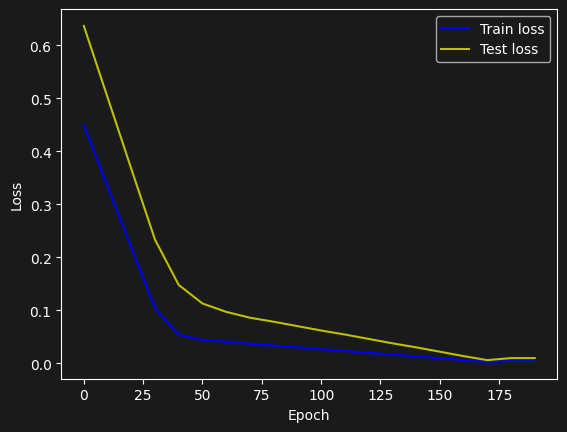

In [171]:

plt.plot(epoch_count, torch.tensor(train_loss_values), c = "b", label = "Train loss")
plt.plot(epoch_count, torch.tensor(test_loss_values), c = "y", label = "Test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()